In [1]:
# 1. INSTALL / IMPORT REQUIRED LIBRARIES

# If a package is missing in your environment, uncomment:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.20

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Dataset Loading

The original notebook used a local path such as:

`D:\Datasets\diabetes_dataset.csv`

That path only works on the original computer. This notebook first looks for a local CSV and, if it is not found, downloads the commonly used **Pima Indians Diabetes** dataset.

Expected columns:

`Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age, Outcome`


In [2]:
# 2. DATASET CONFIGURATION AND LOADING

LOCAL_DATASET = Path("diabetes_dataset.csv")

# Public fallback source for the standard Pima Indians Diabetes dataset.
DATA_URL = (
    "https://raw.githubusercontent.com/jbrownlee/Datasets/master/"
    "pima-indians-diabetes.data.csv"
)

EXPECTED_COLUMNS = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

def load_diabetes_data(local_path=LOCAL_DATASET, url=DATA_URL):
    if Path(local_path).exists():
        print(f"Loading local dataset: {local_path}")
        data = pd.read_csv(local_path)

        # If the local file has no header, assign the standard names.
        if "Outcome" not in data.columns and data.shape[1] == 9:
            data.columns = EXPECTED_COLUMNS
    else:
        print("Local dataset not found.")
        print("Downloading the standard Pima Indians Diabetes dataset...")
        data = pd.read_csv(url, header=None, names=EXPECTED_COLUMNS)

    return data

df = load_diabetes_data()

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()


Local dataset not found.
Dataset loaded successfully.
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# 3. BASIC DATA UNDERSTANDING

print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())


Rows and columns: (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types:


Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Last 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [4]:
# 4. DATA QUALITY CHECK

print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("\nUnique values per column:")
display(df.nunique().to_frame("Unique_Count"))

print("\nBasic statistical summary:")
display(df.describe().T)


Duplicate rows: 0

Missing values:


,Missing_Count
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Unique values per column:


,Unique_Count
Pregnancies,17
Glucose,136
BloodPressure,47
SkinThickness,51
Insulin,186
BMI,248
DiabetesPedigreeFunction,517
Age,52
Outcome,2



Basic statistical summary:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 5. Important Dataset Note: Zero Values

In the Pima dataset, zero is not medically meaningful for some measurements such as:

- Glucose
- BloodPressure
- SkinThickness
- Insulin
- BMI

For machine-learning purposes, these zeros are commonly treated as missing measurements and handled during preprocessing.

We will **not replace them manually before the train/test split**. Instead, the preprocessing is placed inside a scikit-learn `Pipeline`, which helps prevent data leakage.


In [5]:
# 5. CHECK ZERO VALUES

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

zero_summary = (df[zero_columns] == 0).sum().to_frame("Zero_Count")
zero_summary["Zero_Percentage"] = (
    zero_summary["Zero_Count"] / len(df) * 100
).round(2)

display(zero_summary)


,Zero_Count,Zero_Percentage
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


# Exploratory Data Analysis (EDA)

EDA helps us understand:

1. Target distribution
2. Feature distributions
3. Relationships between variables
4. Possible outliers
5. Differences between outcome classes

EDA should be performed to understand the data, while all learned preprocessing/model decisions should be fitted only on training data.


Target counts:


Outcome
0    500
1    268
Name: count, dtype: int64


Target percentages:


Outcome
0    65.1
1    34.9
Name: count, dtype: float64

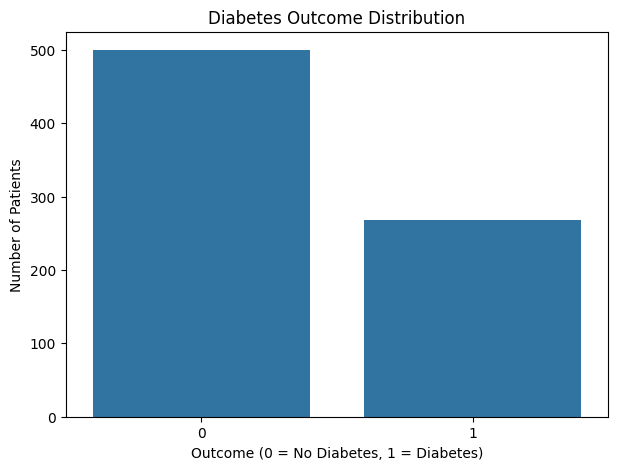

In [6]:
# 6. TARGET DISTRIBUTION

target_counts = df["Outcome"].value_counts().sort_index()

print("Target counts:")
display(target_counts)

print("\nTarget percentages:")
display((target_counts / len(df) * 100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Outcome")
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")
plt.show()


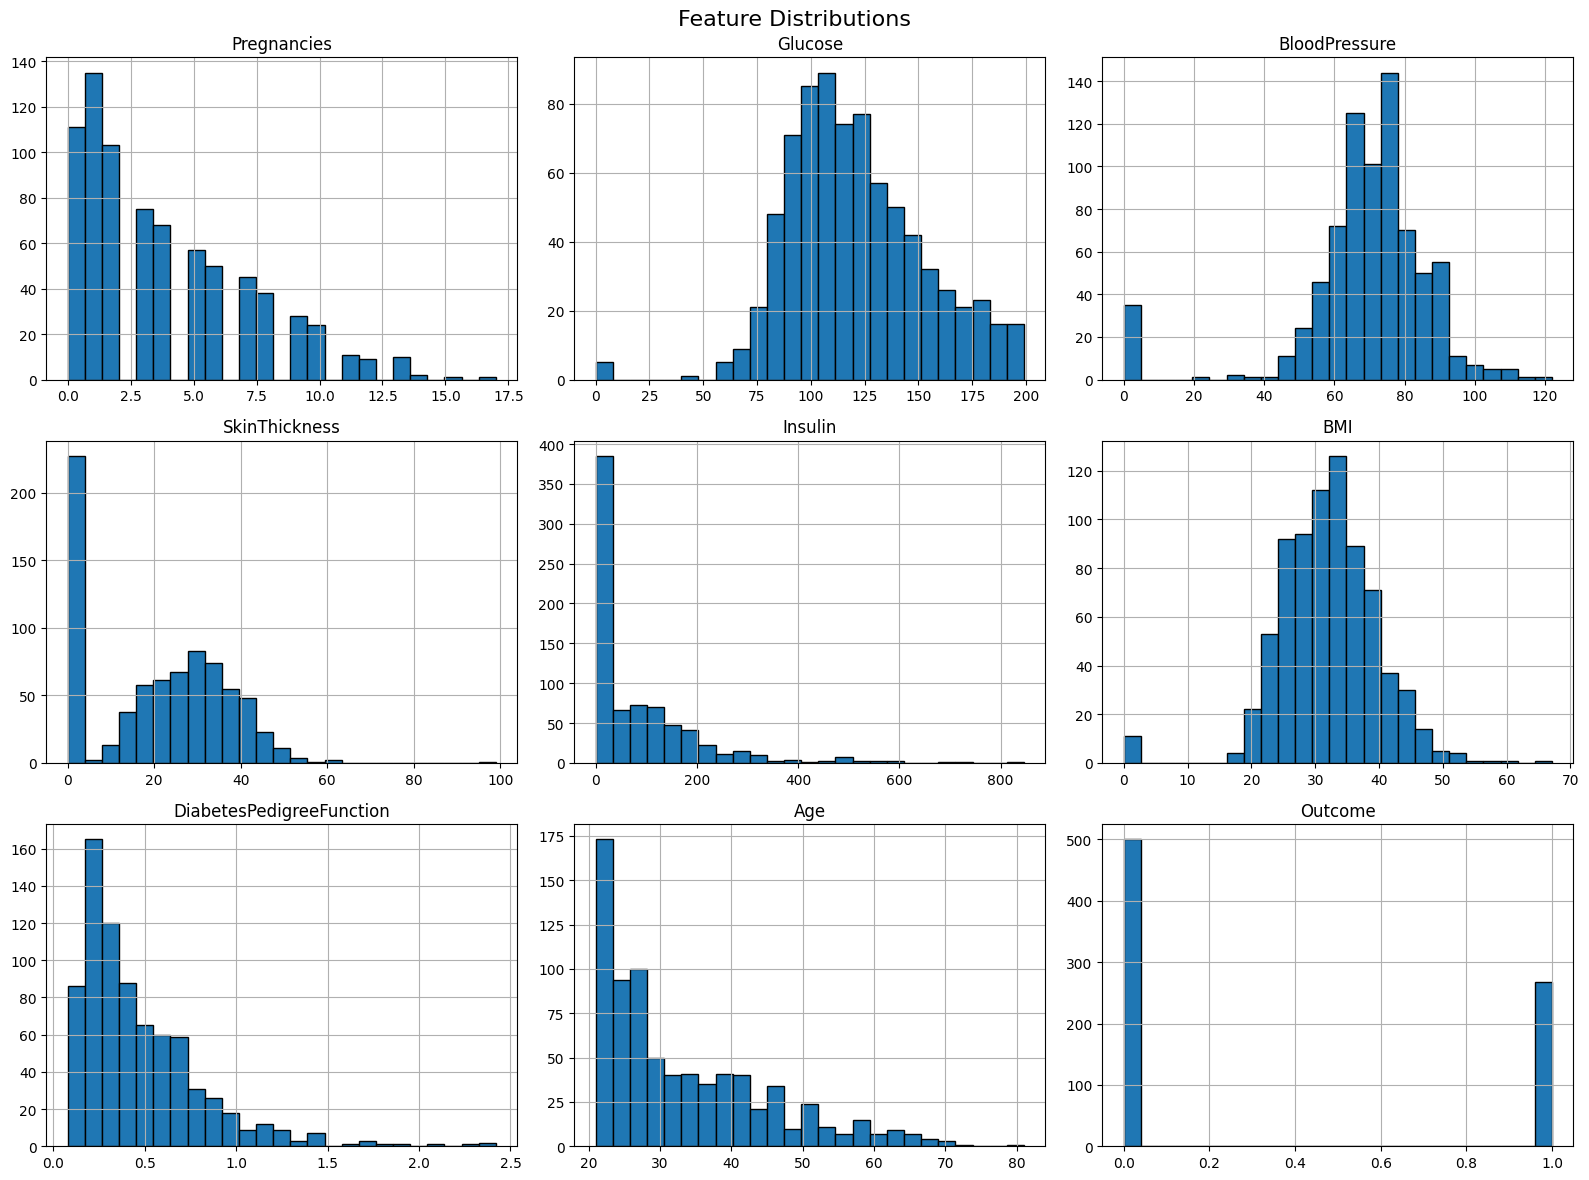

In [7]:

# 7. FEATURE DISTRIBUTIONS

df.hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)
plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()


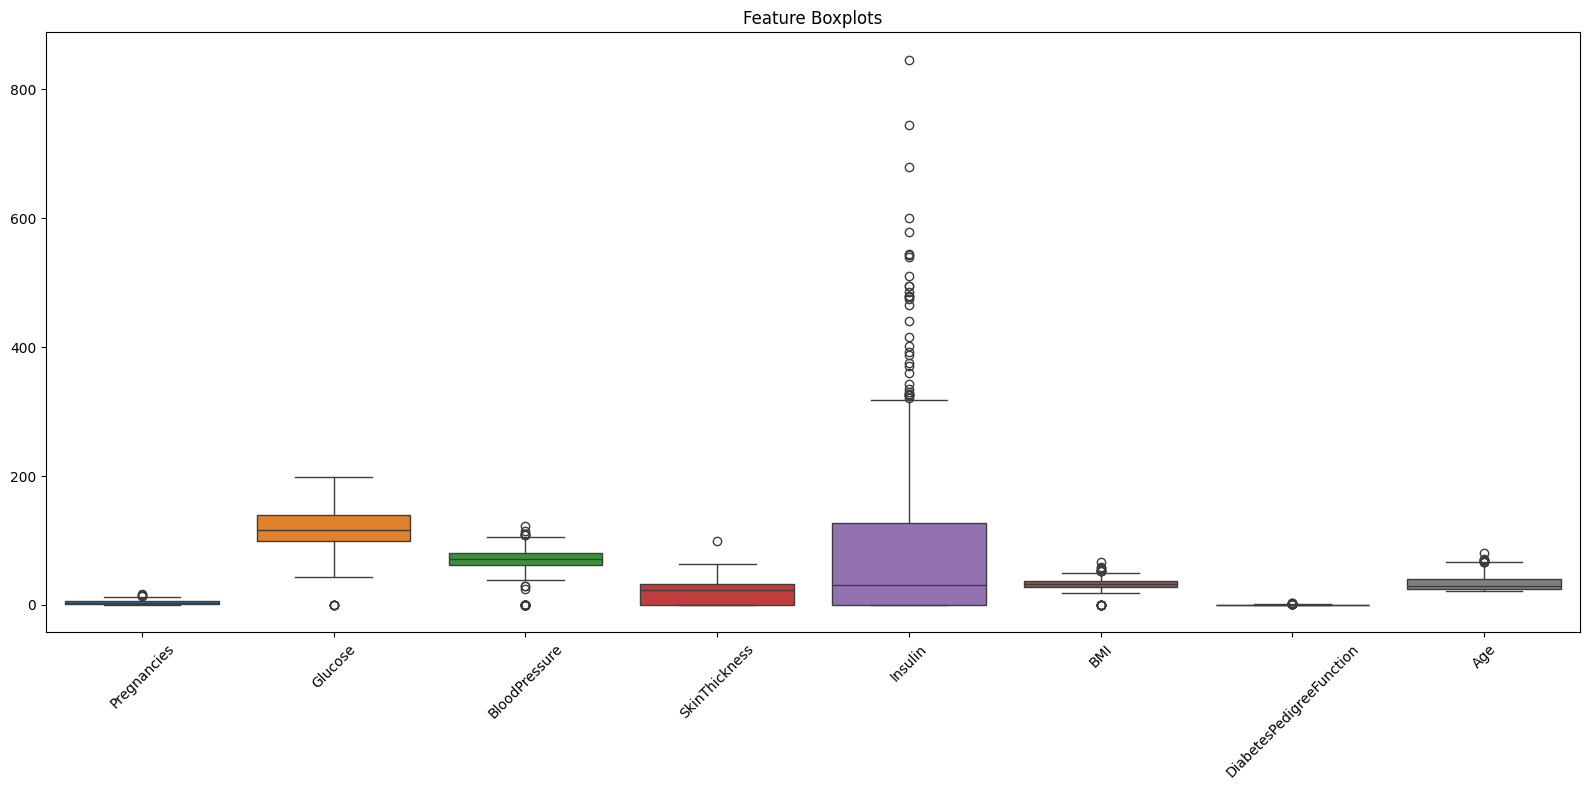

In [8]:
# 8. BOXPLOTS FOR OUTLIER INSPECTION

plt.figure(figsize=(16, 8))
sns.boxplot(data=df.drop(columns="Outcome"))
plt.xticks(rotation=45)
plt.title("Feature Boxplots")
plt.tight_layout()
plt.show()


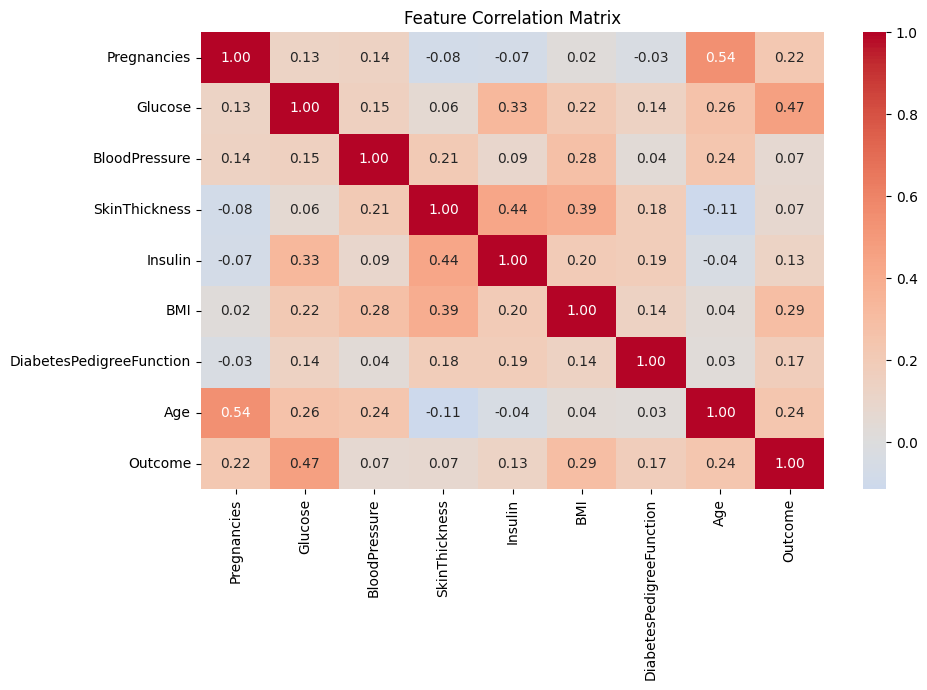

In [9]:
# 9. CORRELATION MATRIX

plt.figure(figsize=(10, 7))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


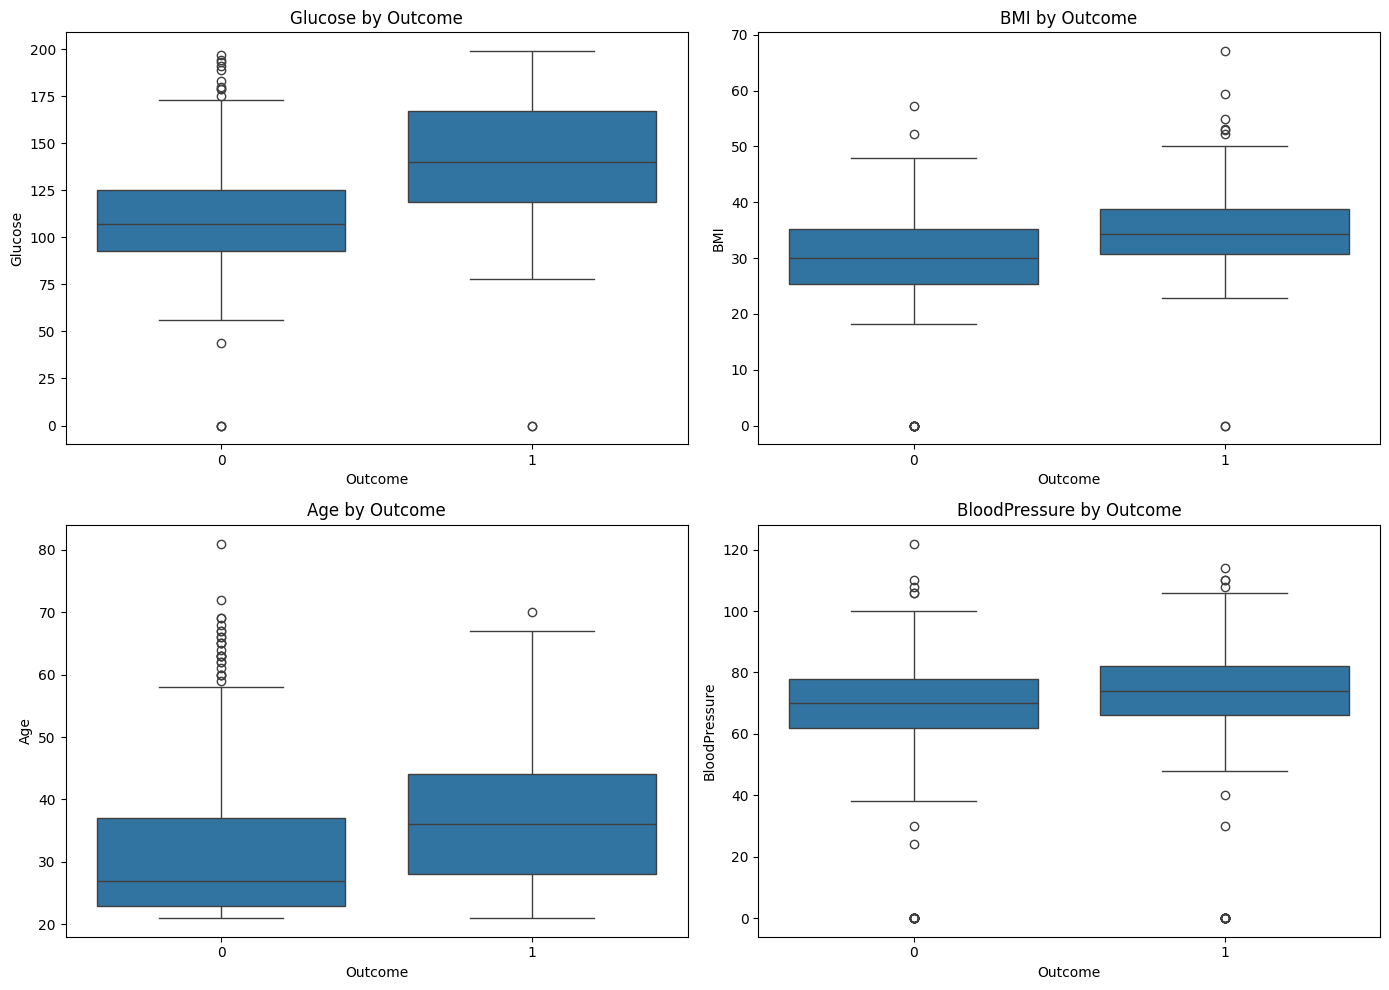

In [10]:
# 10. FEATURE DISTRIBUTIONS BY TARGET

selected_features = ["Glucose", "BMI", "Age", "BloodPressure"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.ravel(), selected_features):
    sns.boxplot(data=df, x="Outcome", y=feature, ax=ax)
    ax.set_title(f"{feature} by Outcome")
    ax.set_xlabel("Outcome")

plt.tight_layout()
plt.show()


# Train/Test Split

We use a **stratified split** so that the class proportion is approximately preserved.

For a simple teaching workflow:

- Training set: used to learn the model
- Test set: kept separate for final evaluation

For hyperparameter tuning, cross-validation is performed **only inside the training data**.


In [11]:
# 11. FEATURES AND TARGET

X = df.drop(columns=["Outcome"]).copy()
y = df["Outcome"].astype(int).copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())


X shape: (768, 8)
y shape: (768,)

Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [12]:
# 12. STRATIFIED TRAIN/TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).sort_index())

print("\nTest target distribution:")
display(y_test.value_counts(normalize=True).sort_index())


Training set: (614, 8)
Test set: (154, 8)

Training target distribution:


Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64


Test target distribution:


Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64

## 13. Preprocessing Pipeline

For the selected measurement columns, zeros are converted to `NaN` **inside the feature data**.

Then `SimpleImputer(strategy="median")` learns replacement values from the training folds.

This is preferable to calculating replacement values from the complete dataset because it reduces data leakage.


In [13]:
# 13. PREPROCESSING

ZERO_AS_MISSING = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

def replace_invalid_zeros(data):
    data = data.copy()
    for col in ZERO_AS_MISSING:
        data[col] = data[col].replace(0, np.nan)
    return data

X_train_clean = replace_invalid_zeros(X_train)
X_test_clean = replace_invalid_zeros(X_test)

print("Missing values created from invalid zeros in training data:")
display(X_train_clean.isnull().sum().to_frame("Missing_Count"))


Missing values created from invalid zeros in training data:


,Missing_Count
Pregnancies,0
Glucose,4
BloodPressure,23
SkinThickness,175
Insulin,290
BMI,9
DiabetesPedigreeFunction,0
Age,0


# 14. Baseline Decision Tree

First, train a basic Decision Tree before tuning it.

A Decision Tree recursively selects features and thresholds to divide the data into increasingly homogeneous groups.

Important hyperparameters include:

- `criterion`
- `max_depth`
- `min_samples_split`
- `min_samples_leaf`
- `class_weight`
- `max_features`


In [14]:
# 14. BASELINE MODEL

baseline_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

baseline_pipeline.fit(X_train_clean, y_train)

baseline_pred = baseline_pipeline.predict(X_test_clean)
baseline_prob = baseline_pipeline.predict_proba(X_test_clean)[:, 1]

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1": f1_score(y_test, baseline_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_prob)
}

display(pd.DataFrame([baseline_metrics]).round(4))


,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.6818,0.5532,0.4815,0.5149,0.6357


In [15]:
# 15. BASELINE CLASSIFICATION REPORT

print(classification_report(
    y_test,
    baseline_pred,
    target_names=["No Diabetes (0)", "Diabetes (1)"],
    zero_division=0
))


                 precision    recall  f1-score   support

No Diabetes (0)       0.74      0.79      0.76       100
   Diabetes (1)       0.55      0.48      0.51        54

       accuracy                           0.68       154
      macro avg       0.65      0.64      0.64       154
   weighted avg       0.67      0.68      0.68       154



# 16. Hyperparameter Tuning

Instead of accepting the default Decision Tree, we search several combinations.

`GridSearchCV` evaluates configurations using stratified cross-validation.

The scoring metric below is **ROC-AUC**, which evaluates ranking quality across classification thresholds.


In [16]:
# 16. GRID SEARCH

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

param_grid = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_search.fit(X_train_clean, y_train)

print("Best CV ROC-AUC:", round(grid_search.best_score_, 4))
print("\nBest parameters:")
print(grid_search.best_params_)


Fitting 5 folds for each of 768 candidates, totalling 3840 fits
Best CV ROC-AUC: 0.7956

Best parameters:
{'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}


In [17]:
# 17. VIEW TOP GRID-SEARCH RESULTS

cv_results = pd.DataFrame(grid_search.cv_results_)

top_results = (
    cv_results[
        [
            "mean_test_score",
            "std_test_score",
            "param_model__criterion",
            "param_model__max_depth",
            "param_model__min_samples_split",
            "param_model__min_samples_leaf",
            "param_model__class_weight"
        ]
    ]
    .sort_values("mean_test_score", ascending=False)
    .head(15)
)

display(top_results.reset_index(drop=True).round(4))


,mean_test_score,std_test_score,param_model__criterion,param_model__max_depth,param_model__min_samples_split,param_model__min_samples_leaf,param_model__class_weight
0,0.7956,0.0203,gini,3,2,1,balanced
1,0.7956,0.0203,gini,3,5,1,balanced
2,0.7956,0.0203,gini,3,20,1,balanced
3,0.7956,0.0203,gini,3,10,1,balanced
4,0.7930,0.0244,gini,3,20,2,balanced
5,0.7930,0.0244,gini,3,5,2,balanced
6,0.7930,0.0244,gini,3,2,2,balanced
7,0.7930,0.0244,gini,3,10,2,balanced
8,0.7927,0.0231,gini,3,20,10,balanced
9,0.7927,0.0231,gini,3,5,10,balanced


# 18. Final Test Evaluation

The best configuration is now evaluated once on the held-out test set.

Do not repeatedly tune hyperparameters against the test set. The test set should remain an estimate of final generalization performance.


In [18]:
# 18. FINAL MODEL EVALUATION

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test_clean)
y_prob = best_model.predict_proba(X_test_clean)[:, 1]

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob)
}

metrics_df = pd.DataFrame([final_metrics], index=["Tuned Decision Tree"])

display(metrics_df.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes (0)", "Diabetes (1)"],
    zero_division=0
))


,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Tuned Decision Tree,0.6753,0.5233,0.8333,0.6429,0.7621,0.5669



Classification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.87      0.59      0.70       100
   Diabetes (1)       0.52      0.83      0.64        54

       accuracy                           0.68       154
      macro avg       0.70      0.71      0.67       154
   weighted avg       0.75      0.68      0.68       154



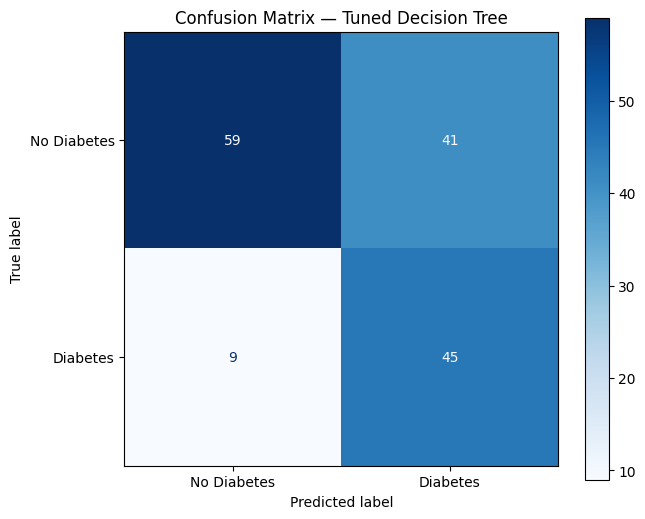

True Negatives : 59
False Positives: 41
False Negatives: 9
True Positives : 45


In [19]:
# 19. CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("Confusion Matrix — Tuned Decision Tree")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)


### Understanding the Confusion Matrix

- **True Positive (TP):** actual diabetes and predicted diabetes
- **True Negative (TN):** actual no diabetes and predicted no diabetes
- **False Positive (FP):** predicted diabetes when actual outcome is no diabetes
- **False Negative (FN):** predicted no diabetes when actual outcome is diabetes

For a medical classification problem, the consequences of false positives and false negatives should be considered with domain experts rather than relying on accuracy alone.


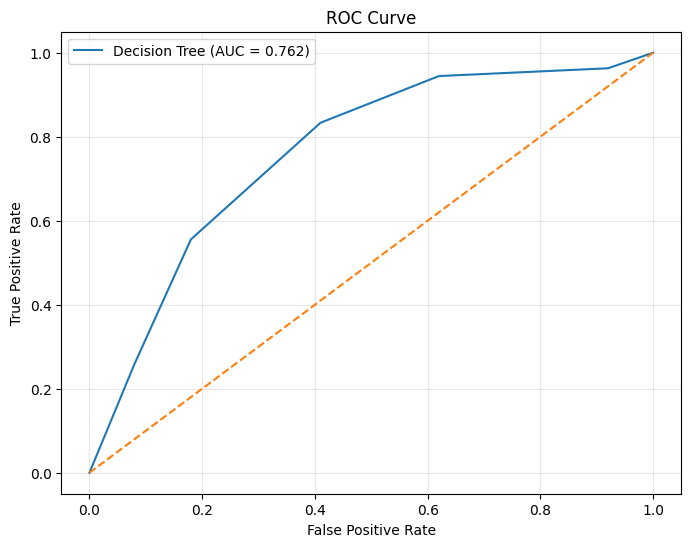

In [20]:
# 20. ROC CURVE

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


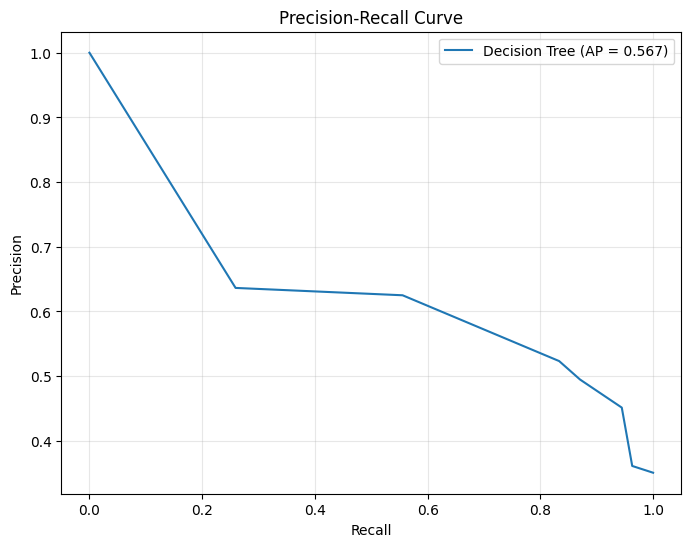

In [21]:
# 21. PRECISION-RECALL CURVE

precision, recall, pr_thresholds = precision_recall_curve(y_test, y_prob)
avg_precision = average_precision_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(
    recall,
    precision,
    label=f"Decision Tree (AP = {avg_precision:.3f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 22. Feature Importance

Decision Trees provide impurity-based feature importance.

This is useful for understanding which features contributed most to the fitted tree, but it should **not automatically be interpreted as causal importance**.

We also calculate permutation importance on the test set as a complementary view.


,Tree_Importance
Glucose,0.613443
BMI,0.220457
Age,0.145026
Insulin,0.021073
SkinThickness,0.000000
BloodPressure,0.000000
Pregnancies,0.000000
DiabetesPedigreeFunction,0.000000


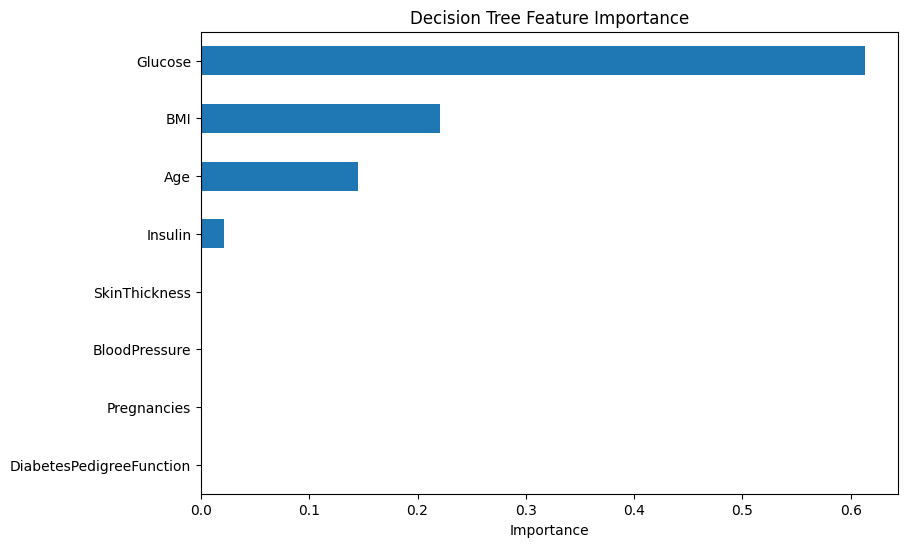

In [22]:
# 22. FEATURE IMPORTANCE

tree_model = best_model.named_steps["model"]

feature_importance = pd.Series(
    tree_model.feature_importances_,
    index=X_train_clean.columns
).sort_values(ascending=False)

display(feature_importance.to_frame("Tree_Importance"))

plt.figure(figsize=(9, 6))
feature_importance.sort_values().plot(kind="barh")
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.show()


,Mean_Permutation_Importance
Glucose,0.0990
BMI,0.0772
Age,0.0316
Pregnancies,0.0000
SkinThickness,0.0000
BloodPressure,0.0000
DiabetesPedigreeFunction,0.0000
Insulin,-0.0055


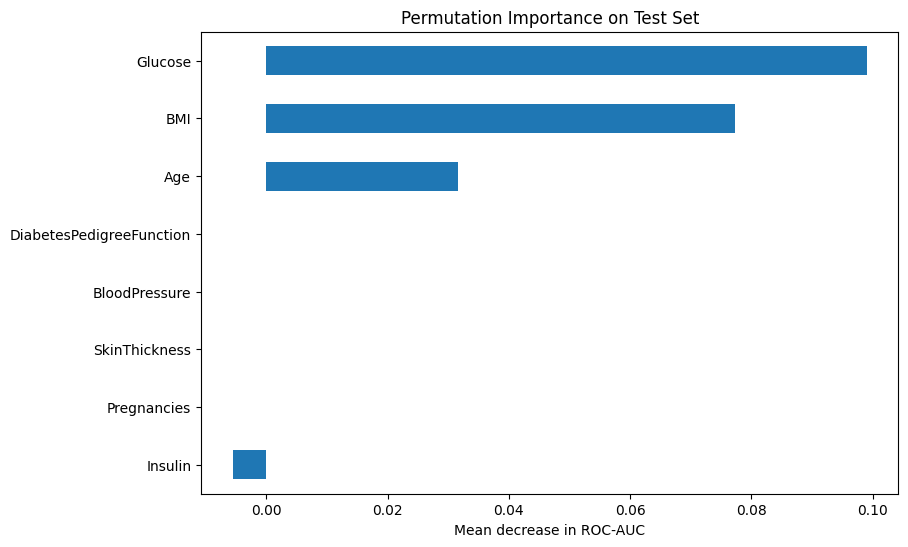

In [23]:

# 23. PERMUTATION IMPORTANCE

perm = permutation_importance(
    best_model,
    X_test_clean,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=X_test_clean.columns
).sort_values(ascending=False)

display(
    perm_importance.to_frame("Mean_Permutation_Importance")
    .round(4)
)

plt.figure(figsize=(9, 6))
perm_importance.sort_values().plot(kind="barh")
plt.title("Permutation Importance on Test Set")
plt.xlabel("Mean decrease in ROC-AUC")
plt.show()


# 24. Visualize the Decision Tree

The original notebook used `pydotplus` and the old `sklearn.externals.six` import.

The modern scikit-learn approach is to use `sklearn.tree.plot_tree`, which avoids that deprecated dependency.


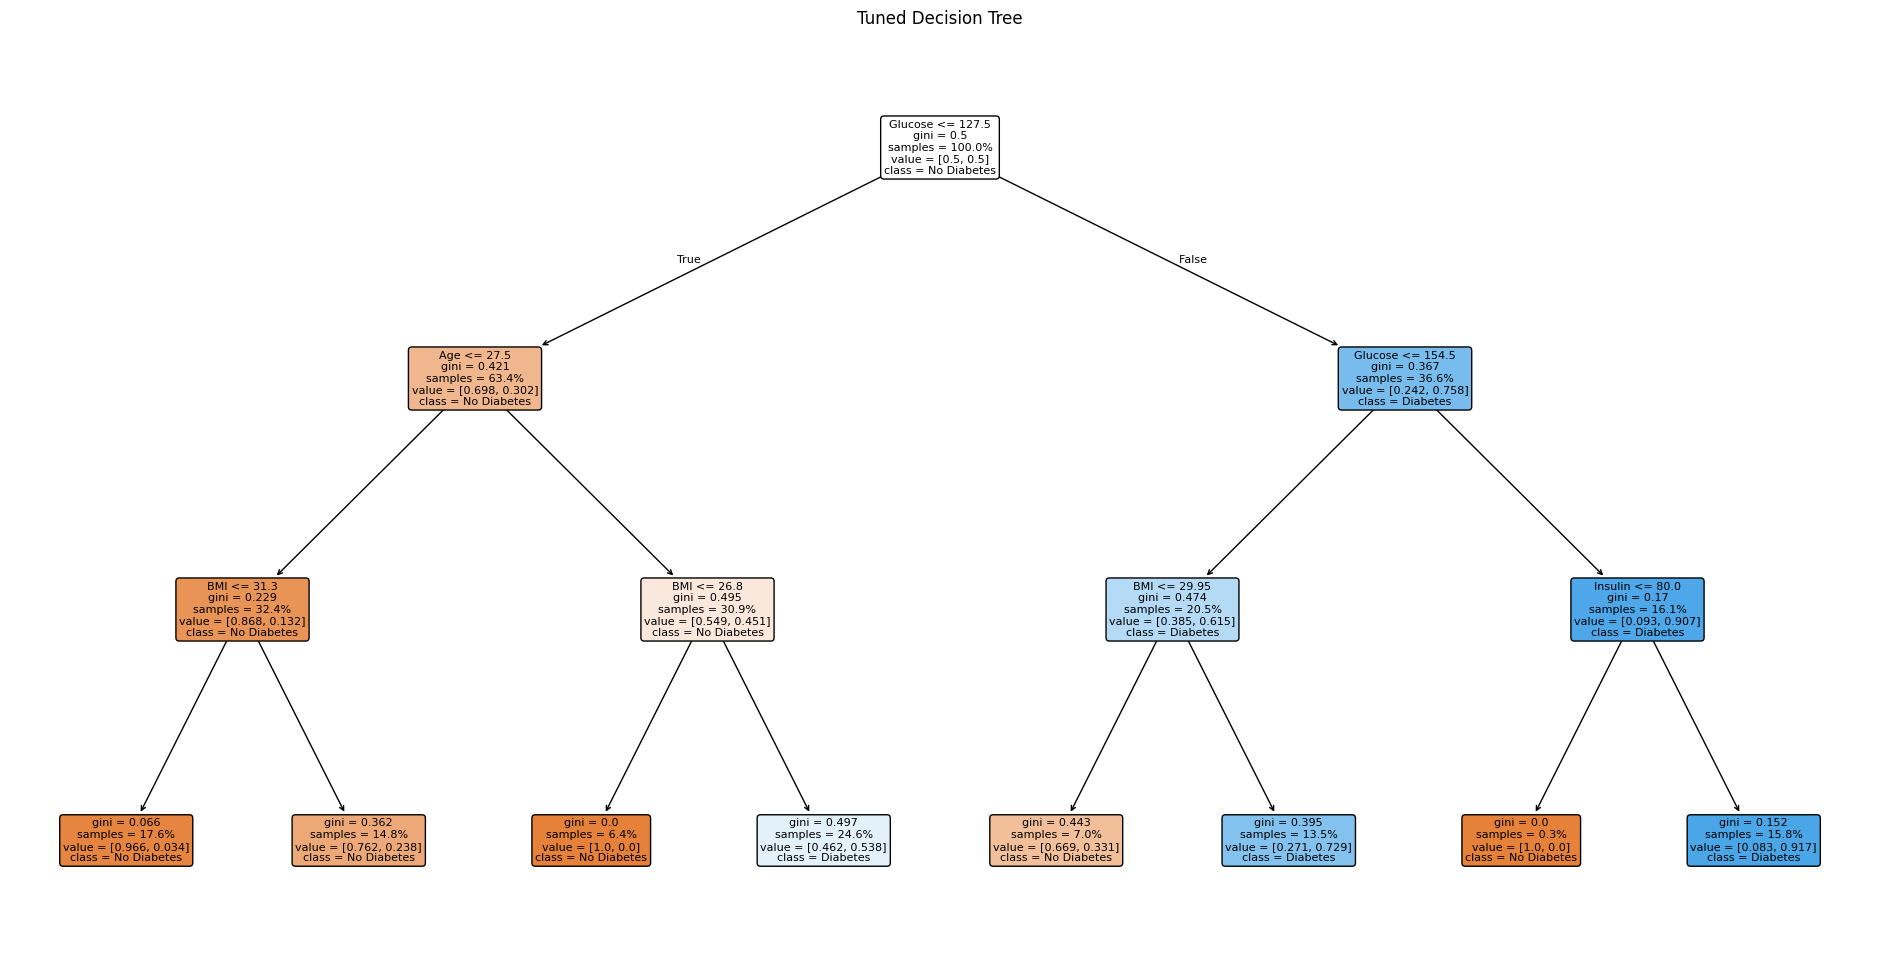

In [24]:
# 24. DECISION TREE VISUALIZATION

plt.figure(figsize=(24, 12))

plot_tree(
    tree_model,
    feature_names=X_train_clean.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=8,
    proportion=True
)

plt.title("Tuned Decision Tree")
plt.show()


# 25. Model Comparison

Compare the baseline and tuned model using the same held-out test set.

This is a descriptive comparison of the measured metrics; the choice of metric should depend on the application's objective and error costs.


,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Model,,,,,,
Baseline Decision Tree,0.6818,0.5532,0.4815,0.5149,0.6357,NaN
Tuned Decision Tree,0.6753,0.5233,0.8333,0.6429,0.7621,0.5669


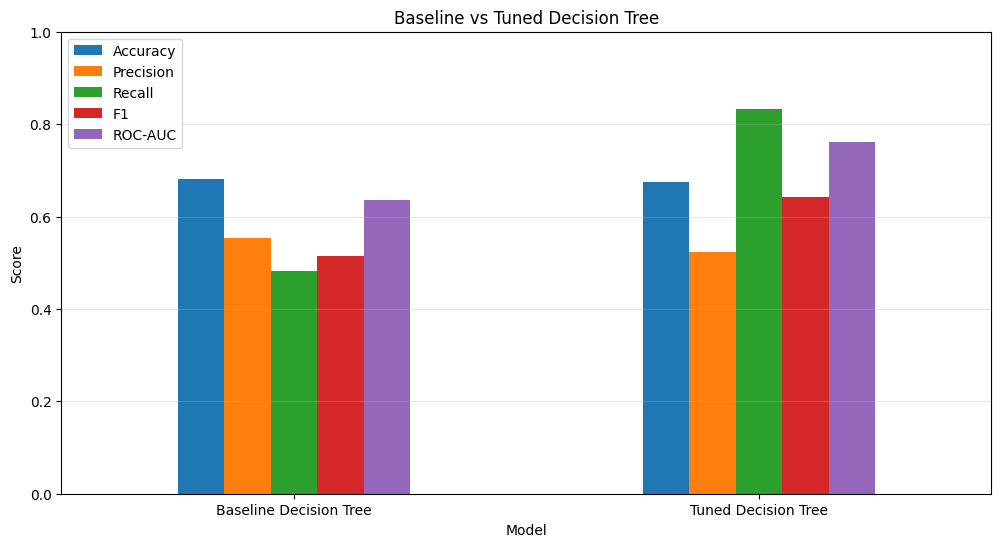

In [25]:
# 25. BASELINE VS TUNED MODEL

comparison = pd.DataFrame([
    {
        "Model": "Baseline Decision Tree",
        **baseline_metrics
    },
    {
        "Model": "Tuned Decision Tree",
        **final_metrics
    }
])

display(comparison.set_index("Model").round(4))

comparison_plot = comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Baseline vs Tuned Decision Tree")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


# 26. Error Analysis

The following table shows cases where the model prediction differs from the actual outcome.

This is useful for identifying patterns in model mistakes.


In [26]:
# 26. ERROR ANALYSIS

error_analysis = X_test_clean.copy()
error_analysis["Actual"] = y_test.values
error_analysis["Predicted"] = y_pred
error_analysis["Predicted_Probability"] = y_prob

errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
].copy()

errors["Error_Type"] = np.where(
    (errors["Actual"] == 0) & (errors["Predicted"] == 1),
    "False Positive",
    "False Negative"
)

print("Number of incorrect predictions:", len(errors))
display(errors.sort_values("Predicted_Probability").head(20))


Number of incorrect predictions: 50


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Actual,Predicted,Predicted_Probability,Error_Type
276,7,106.0,60.0,24.0,NaN,26.5,0.296,29,1,0,0.000000,False Negative
445,0,180.0,78.0,63.0,14.0,59.4,2.420,25,1,0,0.000000,False Negative
6,3,78.0,50.0,32.0,88.0,31.0,0.248,26,1,0,0.034066,False Negative
678,3,121.0,52.0,NaN,NaN,36.0,0.127,25,1,0,0.237530,False Negative
38,2,90.0,68.0,42.0,NaN,38.2,0.503,27,1,0,0.237530,False Negative
198,4,109.0,64.0,44.0,99.0,34.8,0.905,26,1,0,0.237530,False Negative
124,0,113.0,76.0,NaN,NaN,33.3,0.278,23,1,0,0.237530,False Negative
419,3,129.0,64.0,29.0,115.0,26.4,0.219,28,1,0,0.331004,False Negative
722,1,149.0,68.0,29.0,127.0,29.3,0.349,42,1,0,0.331004,False Negative
501,3,84.0,72.0,32.0,NaN,37.2,0.267,28,0,1,0.538258,False Positive


# 27. Predict a New Patient

The input order must match:

1. Pregnancies
2. Glucose
3. BloodPressure
4. SkinThickness
5. Insulin
6. BMI
7. DiabetesPedigreeFunction
8. Age

The function below validates the input and returns the predicted class and probability.


In [27]:
# 27. REUSABLE PREDICTION FUNCTION

FEATURE_NAMES = X.columns.tolist()

def predict_diabetes(
    model,
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree_function,
    age
):
    values = [[
        pregnancies,
        glucose,
        blood_pressure,
        skin_thickness,
        insulin,
        bmi,
        diabetes_pedigree_function,
        age
    ]]

    patient = pd.DataFrame(values, columns=FEATURE_NAMES)
    patient = replace_invalid_zeros(patient)

    prediction = int(model.predict(patient)[0])
    probability = float(model.predict_proba(patient)[0, 1])

    return {
        "Prediction": prediction,
        "Prediction_Label": (
            "Diabetes predicted"
            if prediction == 1
            else "No diabetes predicted"
        ),
        "Probability_of_Diabetes": probability
    }


# Example patient
example_result = predict_diabetes(
    best_model,
    pregnancies=6,
    glucose=148,
    blood_pressure=72,
    skin_thickness=35,
    insulin=0,
    bmi=33.6,
    diabetes_pedigree_function=0.627,
    age=50
)

example_result


{'Prediction': 1,
 'Prediction_Label': 'Diabetes predicted',
 'Probability_of_Diabetes': 0.729275189760382}

> **Medical-use note:** This notebook is an educational machine-learning project. A model prediction is not a medical diagnosis and should not be used by itself for clinical decisions.


# 28. Save the Trained Model

Saving the complete pipeline means the imputation step and Decision Tree are stored together.

This makes inference safer than saving only the raw tree and separately remembering preprocessing steps.


In [28]:
# 28. SAVE MODEL AND METRICS

ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

MODEL_PATH = ARTIFACT_DIR / "diabetes_decision_tree_pipeline.joblib"
METRICS_PATH = ARTIFACT_DIR / "test_metrics.csv"
PARAMS_PATH = ARTIFACT_DIR / "best_parameters.csv"

joblib.dump(best_model, MODEL_PATH)

metrics_df.to_csv(METRICS_PATH)
pd.DataFrame([grid_search.best_params_]).to_csv(
    PARAMS_PATH,
    index=False
)

print("Saved:")
print(MODEL_PATH)
print(METRICS_PATH)
print(PARAMS_PATH)


Saved:
artifacts\diabetes_decision_tree_pipeline.joblib
artifacts\test_metrics.csv
artifacts\best_parameters.csv


In [29]:
# 29. LOAD SAVED MODEL AND TEST INFERENCE

loaded_model = joblib.load(MODEL_PATH)

loaded_result = predict_diabetes(
    loaded_model,
    pregnancies=6,
    glucose=148,
    blood_pressure=72,
    skin_thickness=35,
    insulin=0,
    bmi=33.6,
    diabetes_pedigree_function=0.627,
    age=50
)

loaded_result


{'Prediction': 1,
 'Prediction_Label': 'Diabetes predicted',
 'Probability_of_Diabetes': 0.729275189760382}

# 30. Final Project Checklist

The complete workflow now contains:

- [x] Dataset loading
- [x] Data validation
- [x] Duplicate/missing-value checks
- [x] Statistical summary
- [x] Target distribution
- [x] EDA and visualizations
- [x] Invalid-zero handling
- [x] Stratified train/test split
- [x] Preprocessing pipeline
- [x] Baseline Decision Tree
- [x] Hyperparameter tuning
- [x] Cross-validation
- [x] Accuracy
- [x] Precision
- [x] Recall
- [x] F1-score
- [x] ROC-AUC
- [x] Average Precision
- [x] Confusion matrix
- [x] ROC curve
- [x] Precision-Recall curve
- [x] Feature importance
- [x] Permutation importance
- [x] Tree visualization
- [x] Error analysis
- [x] New-patient prediction
- [x] Model saving/loading
- [x] Reusable inference function
